# 01 · The response matrix

Everything in this project starts from one matrix `Y`:
each **row is a model**, each **column is an MMLU question**, and `Y[m, i] = 1` if model `m` got question `i` right (0 otherwise).

This notebook just looks at that matrix before any modelling.

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")  # for the efficbench loader

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from efficbench import load

# Y: (models x questions) 0/1 matrix; models / items: one row of metadata per model / question
Y, models, items = load()

n_models, n_questions = Y.shape
print(f"{n_models} models x {n_questions} questions")
print(f"overall accuracy: {Y.mean():.3f}")

428 models x 14042 questions
overall accuracy: 0.562


## Model scores and question difficulty
A model's **score** is the fraction of questions it got right (the row mean).
A question's **accuracy** is the fraction of models that got it right (the column mean).

In [2]:
model_scores = Y.mean(axis=1)
question_accuracy = Y.mean(axis=0)

pd.DataFrame({
    "model score": pd.Series(model_scores).describe(),
    "question accuracy": pd.Series(question_accuracy).describe(),
}).round(3)

,model score,question accuracy
count,428.000,14042.000
mean,0.562,0.562
std,0.112,0.300
min,0.252,0.000
25%,0.492,0.292
50%,0.572,0.593
75%,0.634,0.848
max,0.786,0.995


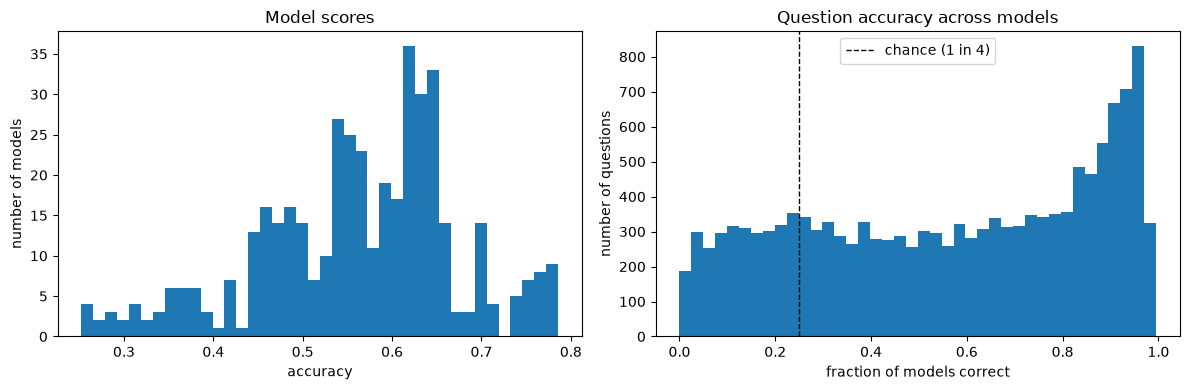

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))

left.hist(model_scores, bins=40)
left.set(title="Model scores", xlabel="accuracy", ylabel="number of models")

right.hist(question_accuracy, bins=40)
right.axvline(0.25, linestyle="--", color="black", linewidth=1, label="chance (1 in 4)")
right.set(
    title="Question accuracy across models",
    xlabel="fraction of models correct",
    ylabel="number of questions",
)
right.legend()

plt.tight_layout()

## The whole matrix
Rows sorted from strongest to weakest model, columns from easiest to hardest question. Black = correct.

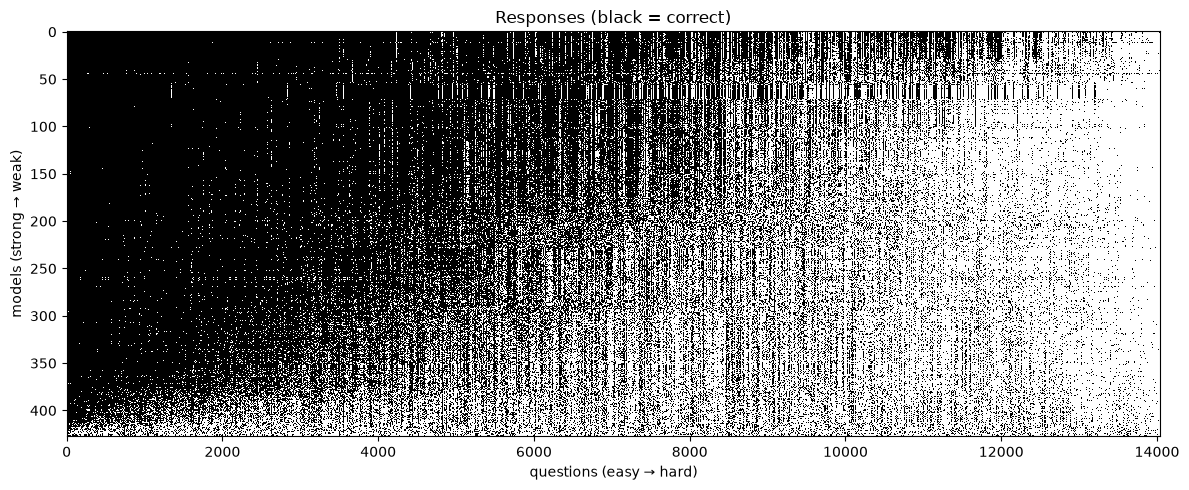

In [4]:
strongest_first = np.argsort(-model_scores)
easiest_first = np.argsort(-question_accuracy)
Y_sorted = Y[strongest_first][:, easiest_first]

fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(Y_sorted, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set(
    title="Responses (black = correct)",
    xlabel="questions (easy → hard)",
    ylabel="models (strong → weak)",
)
plt.tight_layout()

## Accuracy by subject
MMLU has 57 subjects. The number in brackets is how many questions each subject has.

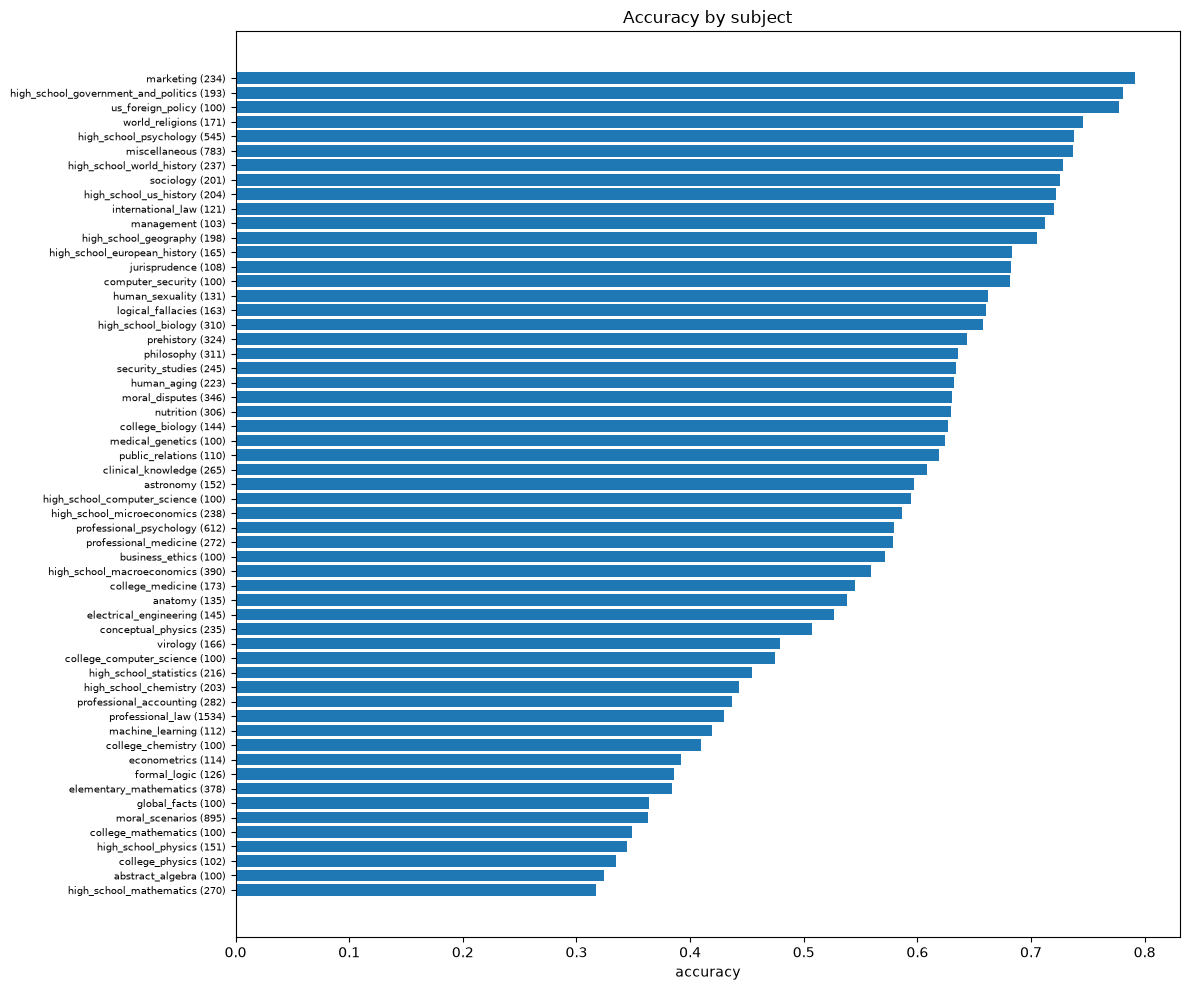

In [5]:
# Average the per-question accuracies within each subject
subject_table = (
    pd.DataFrame({"subject": items.subject, "accuracy": question_accuracy})
    .groupby("subject")
    .agg(accuracy=("accuracy", "mean"), n_questions=("accuracy", "size"))
    .sort_values("accuracy")
)

labels = [
    f"{subject} ({n})"
    for subject, n in zip(subject_table.index, subject_table.n_questions, strict=True)
]

fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(range(len(subject_table)), subject_table.accuracy)
ax.set_yticks(range(len(subject_table)), labels, fontsize=7)
ax.set(title="Accuracy by subject", xlabel="accuracy")
plt.tight_layout()

## How similar are the models to each other?
Correlation between every pair of models' answer vectors. Bright blocks of near-1 correlation are near-duplicate models
(fine-tunes or merges of the same base). If one twin were in train and the other in test, the test would be too easy,
which is why the experiment splits models **by family** instead of at random.

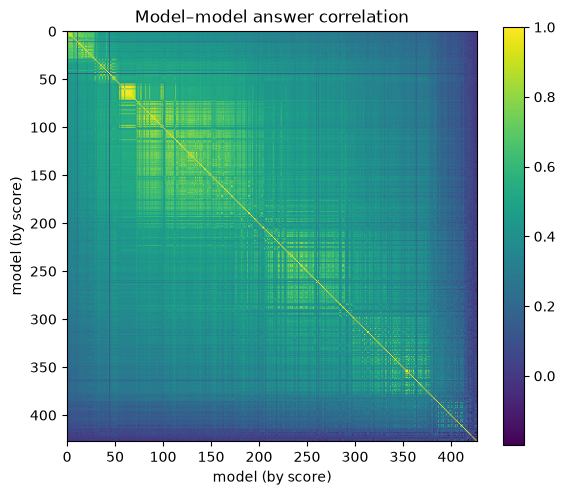

In [6]:
model_correlation = np.corrcoef(Y[strongest_first])

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(model_correlation)
plt.colorbar(image)
ax.set(title="Model–model answer correlation", xlabel="model (by score)", ylabel="model (by score)")
plt.tight_layout()